# Customer Intelligence


# 1. Import the libraries

In [1]:
# ============================================================
# IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json

from pathlib import Path
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

print("Libraries imported successfully.")

Libraries imported successfully.


# 2. Project Paths and Data Loading

In [2]:
# ============================================================
# PROJECT PATHS
# ============================================================

PROJECT_ROOT = Path("..")

DATA_DIR = PROJECT_ROOT / "data"
DATA_CLEAN_DIR = PROJECT_ROOT / "data_clean"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
METADATA_DIR = PROJECT_ROOT / "metadata"
MODEL_DIR = PROJECT_ROOT / "models"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
METADATA_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT.resolve())
print("Data directory:", DATA_DIR.resolve())
print("Clean data directory:", DATA_CLEAN_DIR.resolve())
print("Output directory:", OUTPUT_DIR.resolve())
print("Metadata directory:", METADATA_DIR.resolve())
print("Model directory:", MODEL_DIR.resolve())

Project root: /Users/pansupari/Desktop/Chapter 17 Final Project/RestroDine
Data directory: /Users/pansupari/Desktop/Chapter 17 Final Project/RestroDine/data
Clean data directory: /Users/pansupari/Desktop/Chapter 17 Final Project/RestroDine/data_clean
Output directory: /Users/pansupari/Desktop/Chapter 17 Final Project/RestroDine/outputs
Metadata directory: /Users/pansupari/Desktop/Chapter 17 Final Project/RestroDine/metadata
Model directory: /Users/pansupari/Desktop/Chapter 17 Final Project/RestroDine/models


In [3]:
# ============================================================
# LOAD CUSTOMER INTELLIGENCE DATA
# ============================================================

reviews = pd.read_csv( DATA_CLEAN_DIR / "reviews_clean.csv", parse_dates=["review_date"] )

customers = pd.read_csv( DATA_CLEAN_DIR / "customers_clean.csv", parse_dates=[ "registration_date", "first_order_date" ] )

orders = pd.read_csv( DATA_CLEAN_DIR / "orders_clean.csv", parse_dates=["order_datetime", "order_date"] )

review_aspect_labels = pd.read_csv( DATA_CLEAN_DIR / "review_aspect_labels_clean.csv" )

daily_model = pd.read_csv( DATA_CLEAN_DIR / "daily_model_table_clean.csv", parse_dates=["date"] )

print("Datasets loaded successfully.")

print("Reviews:", reviews.shape)
print("Customers:", customers.shape)
print("Orders:", orders.shape)
print("Aspect labels:", review_aspect_labels.shape)
print("Daily model:", daily_model.shape)

Datasets loaded successfully.
Reviews: (4306, 6)
Customers: (5000, 8)
Orders: (56088, 8)
Aspect labels: (12157, 3)
Daily model: (731, 29)


# 3. Inspect the datasets

In [4]:
# ============================================================
# INSPECT DATASETS
# ============================================================

print("REVIEWS")
display(reviews.head())

print("CUSTOMERS")
display(customers.head())

print("ORDERS")
display(orders.head())

print(" REVIEW ASPECT LABELS")
display(review_aspect_labels.head())

print("DAILY MODEL")
display(daily_model.head())

REVIEWS


,review_id,customer_id,order_id,review_date,rating,review_text
0,R000001,C01584,O000006,2024-01-01,4,Our food arrived quickly. The team was friendl...
1,R000002,C02066,O000015,2024-01-01,5,"Our food arrived quickly. Really tasty food, t..."
2,R000003,C00879,O000010,2024-01-01,4,Prices are fair for the quality. The Beef Burg...
3,R000004,C00382,O000024,2024-01-01,4,The atmosphere was cosy and relaxed. Food was ...
4,R000005,C02254,O000052,2024-01-02,5,Our food arrived quickly. The Lasagne was one ...


CUSTOMERS


,customer_id,customer_name,age,gender,city,registration_date,customer_type,first_order_date
0,C00001,Lea Braun,41,Female,Troisdorf,2021-01-01,Regular,2024-01-18
1,C00002,Bernd Seidel,50,Male,Hürth,2021-01-01,Occasional,2024-07-06
2,C00003,Amira Nguyen,49,Female,Düsseldorf,2021-01-01,Regular,2024-01-03
3,C00004,Lukas Neumann,29,Male,Neuss,2021-01-02,Occasional,2024-01-25
4,C00005,Ida Schröder,36,Female,Düsseldorf,2021-01-02,Regular,2024-02-10


ORDERS


,order_id,customer_id,order_datetime,order_date,order_type,meal_period,order_total,party_size
0,O000001,NaN,2024-01-01 11:46:54,2024-01-01,Dine-in,Lunch,43.80,3
1,O000002,C01367,2024-01-01 12:14:15,2024-01-01,Dine-in,Lunch,34.10,2
2,O000003,NaN,2024-01-01 12:19:10,2024-01-01,Dine-in,Lunch,14.90,1
3,O000004,C01716,2024-01-01 12:20:54,2024-01-01,Takeaway,Lunch,12.90,1
4,O000005,C01866,2024-01-01 12:26:49,2024-01-01,Takeaway,Lunch,23.40,1


 REVIEW ASPECT LABELS


,review_id,aspect,sentiment
0,R000001,Service,Neutral
1,R000001,Staff,Positive
2,R000001,Waiting Time,Positive
3,R000002,Food,Positive
4,R000002,Waiting Time,Positive


DAILY MODEL


,date,revenue,orders,average_order_value,orders_lunch,orders_afternoon,orders_dinner,orders_dine_in,orders_delivery,orders_takeaway,drink_revenue,day_of_week,day_of_week_num,month,month_name,quarter,week_of_year,is_weekend,restaurant_peak_day,restaurant_day_type,holiday_name,is_holiday,temperature_avg_c,temp_max_c,temp_min_c,precipitation_mm,is_rainy,weather_condition,is_promo_day
0,2024-01-01,"1,396.30",40,34.91,16,0,24,23,12,5,229.10,Monday,1,1,January,1,1,False,0,Quiet,New Year's Day,True,3.80,7.00,1.30,1.30,True,Rain,False
1,2024-01-02,"2,118.00",56,37.82,24,6,26,30,20,6,353.40,Tuesday,2,1,January,1,1,False,0,Quiet,NaN,False,1.30,3.60,-0.50,0.00,False,Cold,False
2,2024-01-03,"1,527.30",50,30.55,16,2,32,23,15,12,278.80,Wednesday,3,1,January,1,1,False,0,Quiet,NaN,False,3.40,5.30,1.90,7.00,True,Rain,False
3,2024-01-04,"2,532.30",67,37.80,20,1,46,41,17,9,473.00,Thursday,4,1,January,1,1,False,0,Medium,NaN,False,5.70,6.80,4.80,1.00,True,Rain,False
4,2024-01-05,"3,420.70",91,37.59,21,11,59,52,31,8,637.90,Friday,5,1,January,1,1,False,1,Peak,NaN,False,-0.10,1.30,-1.20,3.30,True,Rain,False


In [5]:
# ============================================================
# CHECK DATASET COVERAGE
# ============================================================

print("Review period:", reviews["review_date"].min().date(), "to", reviews["review_date"].max().date() )

print("\nUnique customers with reviews:", reviews["customer_id"].nunique())

print("\nUnique reviewed orders:", reviews["order_id"].nunique())

print("\nUnique customers in customer table:", customers["customer_id"].nunique())

print("\nUnique customers in orders:", orders["customer_id"].nunique())

print("\nUnique orders in daily model:", daily_model["date"].nunique())

Review period: 2024-01-01 to 2025-12-31

Unique customers with reviews: 2030

Unique reviewed orders: 4306

Unique customers in customer table: 5000

Unique customers in orders: 3841

Unique orders in daily model: 731


# 4. Data validation and cleaning

In [6]:
# ============================================================
# DATA QUALITY CHECKS
# ============================================================

print("Missing values in reviews:")
display(reviews.isna().sum())

print("Duplicate review IDs:")
print(reviews["review_id"].duplicated().sum())

print("Duplicate customer IDs:")
print(customers["customer_id"].duplicated().sum())

print("Duplicate order IDs:")
print(orders["order_id"].duplicated().sum())

print("Duplicate review-aspect combinations:")
print(
    review_aspect_labels.duplicated(
        subset=["review_id", "aspect"]
    ).sum()
)

Missing values in reviews:


review_id      0
customer_id    0
order_id       0
review_date    0
rating         0
review_text    0
dtype: int64

Duplicate review IDs:
0
Duplicate customer IDs:
0
Duplicate order IDs:
0
Duplicate review-aspect combinations:
0


In [7]:
# ============================================================
# CLEAN REVIEW DATA
# ============================================================

reviews_clean = reviews.copy()

reviews_clean["review_text"] = ( reviews_clean["review_text"] .fillna("") .astype(str) .str.strip() )

reviews_clean = reviews_clean[
    (reviews_clean["review_text"] != "") &
    (reviews_clean["rating"].between(1, 5))
].copy()

reviews_clean = reviews_clean.drop_duplicates( subset="review_id" )

reviews_clean["rating"] = ( reviews_clean["rating"].astype(int) )

print("Original reviews:", len(reviews))
print("Clean reviews:", len(reviews_clean))
print("Removed records:", len(reviews) - len(reviews_clean))

Original reviews: 4306
Clean reviews: 4306
Removed records: 0


In [8]:
# ============================================================
# VALIDATE REVIEW RELATIONSHIPS
# ============================================================

unknown_customers = ~reviews_clean["customer_id"].isin(
    customers["customer_id"]
)

unknown_orders = ~reviews_clean["order_id"].isin(
    orders["order_id"]
)

print(
    "Reviews with unknown customers:",
    unknown_customers.sum()
)

print(
    "Reviews with unknown orders:",
    unknown_orders.sum()
)

print(
    "Review IDs in aspect labels but not reviews:",
    (~review_aspect_labels["review_id"].isin(
        reviews_clean["review_id"]
    )).sum()
)

Reviews with unknown customers: 0
Reviews with unknown orders: 0
Review IDs in aspect labels but not reviews: 0


# 5. Review exploratory data analysis

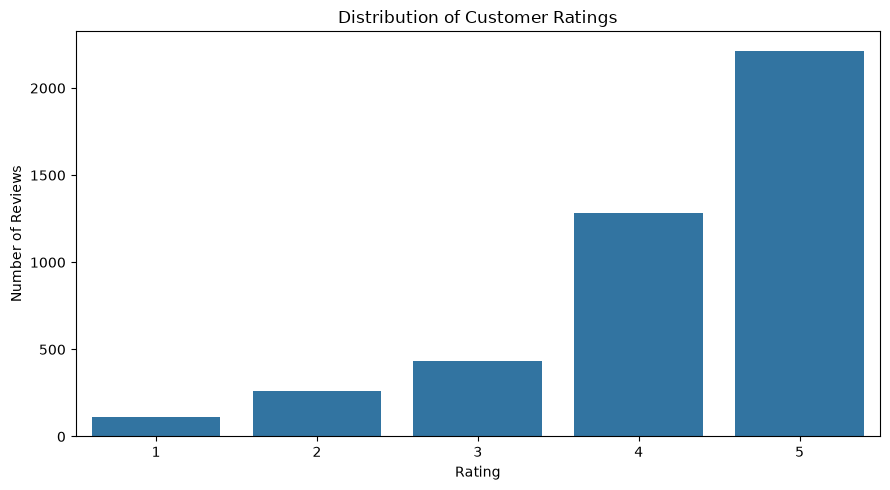

,Number of Reviews
rating,
1,110
2,263
3,434
4,1284
5,2215


In [9]:
# ============================================================
# REVIEW RATING DISTRIBUTION
# ============================================================

rating_counts = (
    reviews_clean["rating"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(9, 5))

sns.countplot(
    data=reviews_clean,
    x="rating",
    order=[1, 2, 3, 4, 5]
)

plt.title("Distribution of Customer Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

display(rating_counts.rename("Number of Reviews").to_frame())

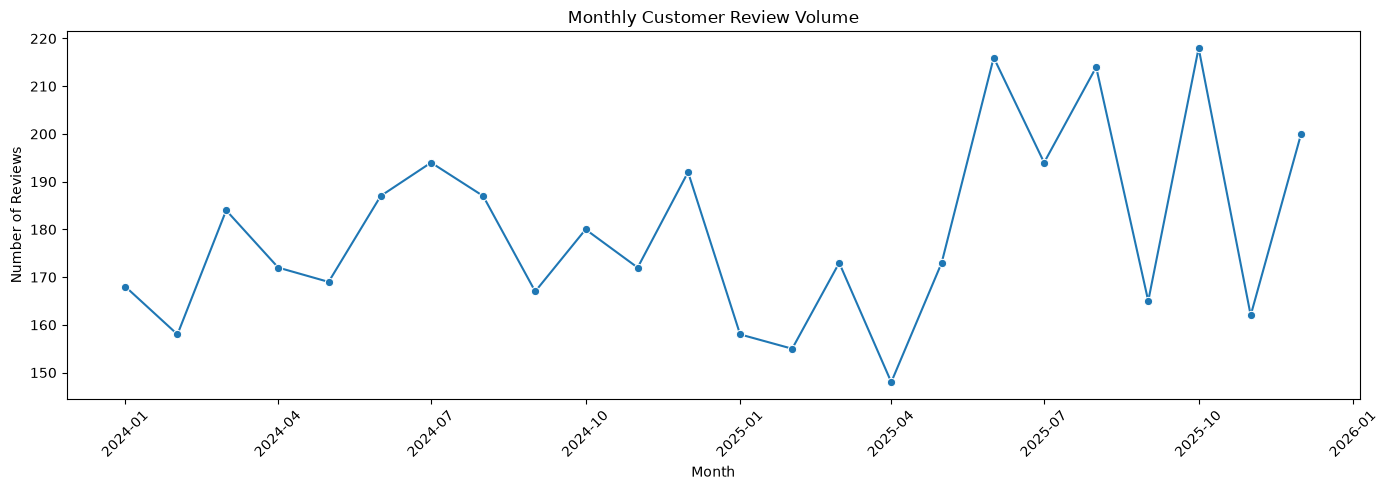

/var/folders/lk/_pf4928d6_x99xld7btjlldc0000gn/T/ipykernel_4342/1861810661.py:39: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(monthly_reviews.round(2).head())


,review_month,review_count,average_rating
0,2024-01-01,168,4.17
1,2024-02-01,158,4.14
2,2024-03-01,184,4.37
3,2024-04-01,172,4.23
4,2024-05-01,169,4.30


In [10]:
# ============================================================
# MONTHLY REVIEW VOLUME
# ============================================================

reviews_clean["review_month"] = (
    reviews_clean["review_date"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

monthly_reviews = (
    reviews_clean
    .groupby("review_month")
    .agg(
        review_count=("review_id", "count"),
        average_rating=("rating", "mean")
    )
    .reset_index()
)

fig, ax1 = plt.subplots(figsize=(14, 5))

sns.lineplot(
    data=monthly_reviews,
    x="review_month",
    y="review_count",
    marker="o",
    ax=ax1
)

ax1.set_title("Monthly Customer Review Volume")
ax1.set_xlabel("Month")
ax1.set_ylabel("Number of Reviews")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(monthly_reviews.round(2).head())

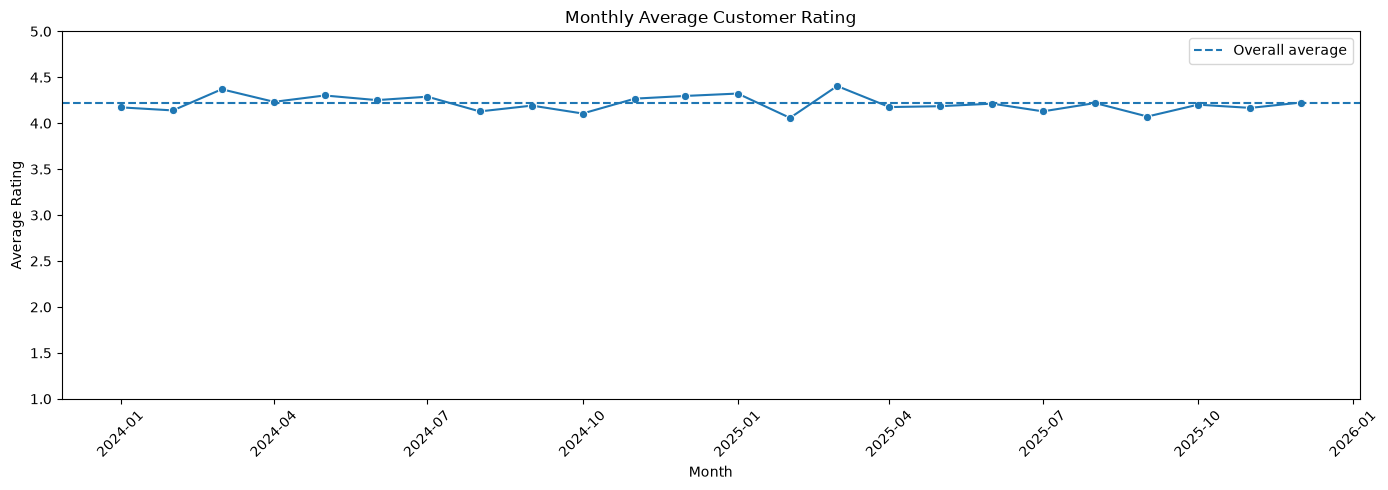

Overall average rating: 4.21


In [11]:
# ============================================================
# MONTHLY AVERAGE CUSTOMER RATING
# ============================================================

plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_reviews,
    x="review_month",
    y="average_rating",
    marker="o"
)

plt.axhline(
    reviews_clean["rating"].mean(),
    linestyle="--",
    label="Overall average"
)

plt.title("Monthly Average Customer Rating")
plt.xlabel("Month")
plt.ylabel("Average Rating")
plt.ylim(1, 5)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(
    "Overall average rating:",
    round(reviews_clean["rating"].mean(), 2)
)

In [12]:
# ============================================================
# CREATE MASTER CUSTOMER FEEDBACK DATASET
# ============================================================

# Start with the aspect-level labels and attach review information
customer_feedback = review_aspect_labels.merge(
    reviews,
    on="review_id",
    how="inner",
    validate="many_to_one"
)


# Attach customer information
customer_feedback = customer_feedback.merge(
    customers[
        ["customer_id", "customer_type"]
    ],
    on="customer_id",
    how="left",
    validate="many_to_one"
)


# Attach order information
customer_feedback = customer_feedback.merge(
    orders[
        [
            "order_id",
            "order_datetime",
            "order_type",
            "meal_period",
            "order_total"
        ]
    ],
    on="order_id",
    how="left",
    validate="many_to_one"
)


# Create additional date columns
customer_feedback["review_month"] = (
    customer_feedback["review_date"].dt.to_period("M").astype(str)
)

customer_feedback["review_year"] = (
    customer_feedback["review_date"].dt.year
)


# Sort the dataset
customer_feedback = customer_feedback.sort_values(
    ["review_date", "review_id", "aspect"]
).reset_index(drop=True)


print("Master customer feedback dataset created.")

print("Shape:", customer_feedback.shape)

display(customer_feedback.head())

Master customer feedback dataset created.
Shape: (12157, 15)


,review_id,aspect,sentiment,customer_id,order_id,review_date,rating,review_text,customer_type,order_datetime,order_type,meal_period,order_total,review_month,review_year
0,R000001,Service,Neutral,C01584,O000006,2024-01-01,4,Our food arrived quickly. The team was friendl...,Regular,2024-01-01 12:41:39,Delivery,Lunch,74.90,2024-01,2024
1,R000001,Staff,Positive,C01584,O000006,2024-01-01,4,Our food arrived quickly. The team was friendl...,Regular,2024-01-01 12:41:39,Delivery,Lunch,74.90,2024-01,2024
2,R000001,Waiting Time,Positive,C01584,O000006,2024-01-01,4,Our food arrived quickly. The team was friendl...,Regular,2024-01-01 12:41:39,Delivery,Lunch,74.90,2024-01,2024
3,R000002,Food,Positive,C02066,O000015,2024-01-01,5,"Our food arrived quickly. Really tasty food, t...",Occasional,2024-01-01 14:08:11,Delivery,Lunch,86.20,2024-01,2024
4,R000002,Waiting Time,Positive,C02066,O000015,2024-01-01,5,"Our food arrived quickly. Really tasty food, t...",Occasional,2024-01-01 14:08:11,Delivery,Lunch,86.20,2024-01,2024


In [13]:
# ============================================================
# OVERALL CUSTOMER FEEDBACK KPIs
# ============================================================

total_reviews = reviews["review_id"].nunique()

total_customers_reviewed = reviews["customer_id"].nunique()

average_rating = reviews["rating"].mean()

total_aspect_mentions = len(customer_feedback)

positive_mentions = (
    customer_feedback["sentiment"] == "Positive"
).sum()

neutral_mentions = (
    customer_feedback["sentiment"] == "Neutral"
).sum()

negative_mentions = (
    customer_feedback["sentiment"] == "Negative"
).sum()


positive_share = (
    positive_mentions / total_aspect_mentions * 100
    if total_aspect_mentions > 0 else 0
)

neutral_share = (
    neutral_mentions / total_aspect_mentions * 100
    if total_aspect_mentions > 0 else 0
)

negative_share = (
    negative_mentions / total_aspect_mentions * 100
    if total_aspect_mentions > 0 else 0
)


customer_kpis = pd.DataFrame({
    "Metric": [
        "Total Reviews",
        "Customers Who Reviewed",
        "Average Rating",
        "Aspect Mentions",
        "Positive Sentiment (%)",
        "Neutral Sentiment (%)",
        "Negative Sentiment (%)"
    ],
    "Value": [
        total_reviews,
        total_customers_reviewed,
        round(average_rating, 2),
        total_aspect_mentions,
        round(positive_share, 2),
        round(neutral_share, 2),
        round(negative_share, 2)
    ]
})


display(customer_kpis)

,Metric,Value
0,Total Reviews,"4,306.00"
1,Customers Who Reviewed,"2,030.00"
2,Average Rating,4.21
3,Aspect Mentions,"12,157.00"
4,Positive Sentiment (%),73.23
5,Neutral Sentiment (%),12.69
6,Negative Sentiment (%),14.07


# 6. Aspect sentiment analysis

In [14]:
# ============================================================
# ASPECT SENTIMENT ANALYSIS
# ============================================================

# Count sentiment mentions for each aspect
aspect_sentiment = pd.crosstab(
    customer_feedback["aspect"],
    customer_feedback["sentiment"]
)


# Ensure all three sentiment columns exist
for sentiment in ["Positive", "Neutral", "Negative"]:

    if sentiment not in aspect_sentiment.columns:
        aspect_sentiment[sentiment] = 0


# Keep a consistent column order
aspect_sentiment = aspect_sentiment[
    ["Positive", "Neutral", "Negative"]
]


# Calculate total mentions per aspect
aspect_sentiment["Total Mentions"] = (
    aspect_sentiment[
        ["Positive", "Neutral", "Negative"]
    ].sum(axis=1)
)


# Calculate sentiment percentages
for sentiment in ["Positive", "Neutral", "Negative"]:

    aspect_sentiment[f"{sentiment} (%)"] = (
        aspect_sentiment[sentiment]
        / aspect_sentiment["Total Mentions"]
        * 100
    )


aspect_sentiment = aspect_sentiment.reset_index()


aspect_sentiment = aspect_sentiment.sort_values(
    "Negative (%)",
    ascending=False
).reset_index(drop=True)


display(aspect_sentiment)

sentiment,aspect,Positive,Neutral,Negative,Total Mentions,Positive (%),Neutral (%),Negative (%)
0,Waiting Time,961,236,489,1686,57.00,14.00,29.00
1,Service,1259,241,310,1810,69.56,13.31,17.13
2,Price,823,158,168,1149,71.63,13.75,14.62
3,Staff,1016,156,168,1340,75.82,11.64,12.54
4,Food,2870,436,379,3685,77.88,11.83,10.28
5,Drinks,489,89,59,637,76.77,13.97,9.26
6,Atmosphere,1108,170,110,1388,79.83,12.25,7.93
7,Cleanliness,377,57,28,462,81.60,12.34,6.06


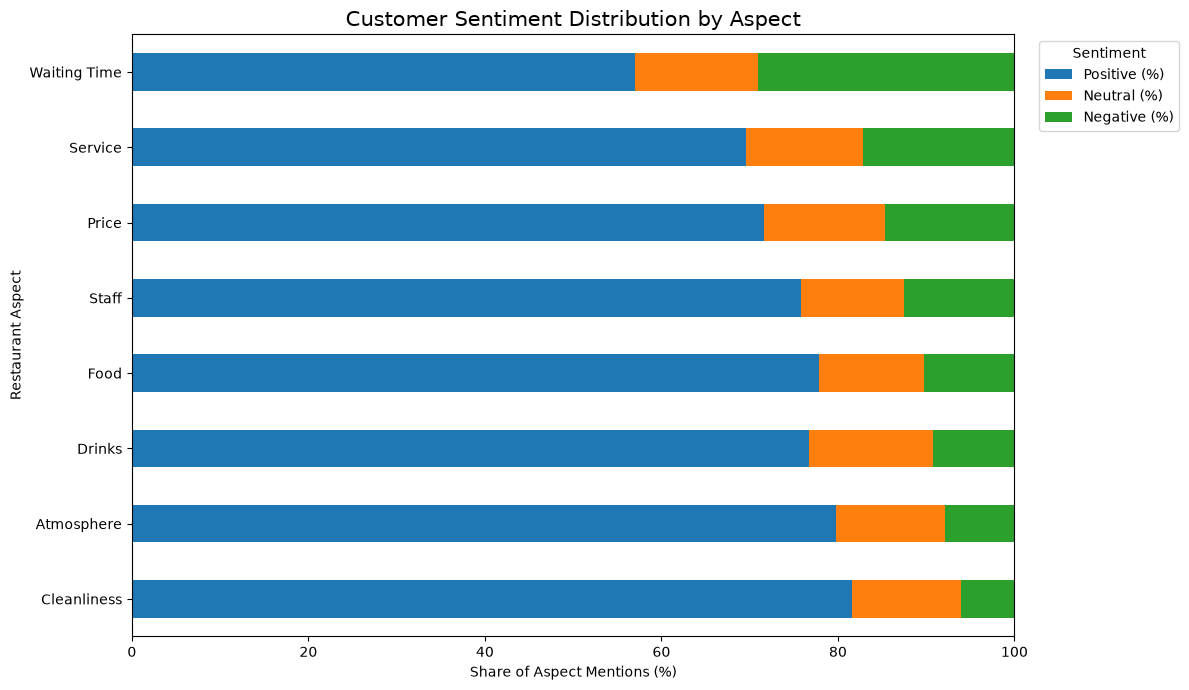

In [15]:
# ============================================================
# SENTIMENT DISTRIBUTION BY ASPECT
# ============================================================

plot_data = aspect_sentiment.set_index("aspect")[
    [
        "Positive (%)",
        "Neutral (%)",
        "Negative (%)"
    ]
]

plot_data = plot_data.sort_values("Negative (%)")


ax = plot_data.plot(
    kind="barh",
    stacked=True,
    figsize=(12, 7)
)

ax.set_title(
    "Customer Sentiment Distribution by Aspect",
    fontsize=15
)

ax.set_xlabel("Share of Aspect Mentions (%)")

ax.set_ylabel("Restaurant Aspect")

ax.legend(
    title="Sentiment",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

# 7. Identify areas for improvement

In [16]:
# ============================================================
# IDENTIFY AREAS FOR IMPROVEMENT
# ============================================================

improvement_areas = aspect_sentiment[
    [
        "aspect",
        "Total Mentions",
        "Negative",
        "Negative (%)",
        "Positive (%)"
    ]
].copy()


improvement_areas = improvement_areas.rename(
    columns={
        "aspect": "Aspect",
        "Total Mentions": "Total Mentions",
        "Negative": "Negative Mentions",
        "Negative (%)": "Negative Share (%)",
        "Positive (%)": "Positive Share (%)"
    }
)


# Rank by negative share, then by volume of negative mentions
improvement_areas = improvement_areas.sort_values(
    ["Negative Share (%)", "Negative Mentions"],
    ascending=False
).reset_index(drop=True)


improvement_areas.insert(
    0,
    "Priority Rank",
    range(1, len(improvement_areas) + 1)
)


display(improvement_areas)

sentiment,Priority Rank,Aspect,Total Mentions,Negative Mentions,Negative Share (%),Positive Share (%)
0,1,Waiting Time,1686,489,29.00,57.00
1,2,Service,1810,310,17.13,69.56
2,3,Price,1149,168,14.62,71.63
3,4,Staff,1340,168,12.54,75.82
4,5,Food,3685,379,10.28,77.88
5,6,Drinks,637,59,9.26,76.77
6,7,Atmosphere,1388,110,7.93,79.83
7,8,Cleanliness,462,28,6.06,81.60


Track how positive, neutral, and negative feedback changes over time.

In [17]:
# ============================================================
# MONTHLY SENTIMENT TRENDS
# ============================================================

monthly_sentiment = (
    customer_feedback
    .groupby(["review_month", "sentiment"])
    .size()
    .unstack(fill_value=0)
)


# Ensure all sentiment categories exist
for sentiment in ["Positive", "Neutral", "Negative"]:

    if sentiment not in monthly_sentiment.columns:
        monthly_sentiment[sentiment] = 0


monthly_sentiment = monthly_sentiment[
    ["Positive", "Neutral", "Negative"]
]


monthly_sentiment = monthly_sentiment.sort_index()


# Calculate monthly total mentions
monthly_sentiment["Total Mentions"] = (
    monthly_sentiment.sum(axis=1)
)


# Calculate monthly negative share
monthly_sentiment["Negative (%)"] = (
    monthly_sentiment["Negative"]
    / monthly_sentiment["Total Mentions"]
    * 100
)


monthly_sentiment = monthly_sentiment.reset_index()


display(monthly_sentiment.head(12))

sentiment,review_month,Positive,Neutral,Negative,Total Mentions,Negative (%)
0,2024-01,354,56,65,475,13.68
1,2024-02,307,57,60,424,14.15
2,2024-03,407,57,52,516,10.08
3,2024-04,355,59,55,469,11.73
4,2024-05,369,58,60,487,12.32
5,2024-06,382,57,87,526,16.54
6,2024-07,409,74,77,560,13.75
7,2024-08,383,64,92,539,17.07
8,2024-09,349,62,62,473,13.11
9,2024-10,355,61,89,505,17.62


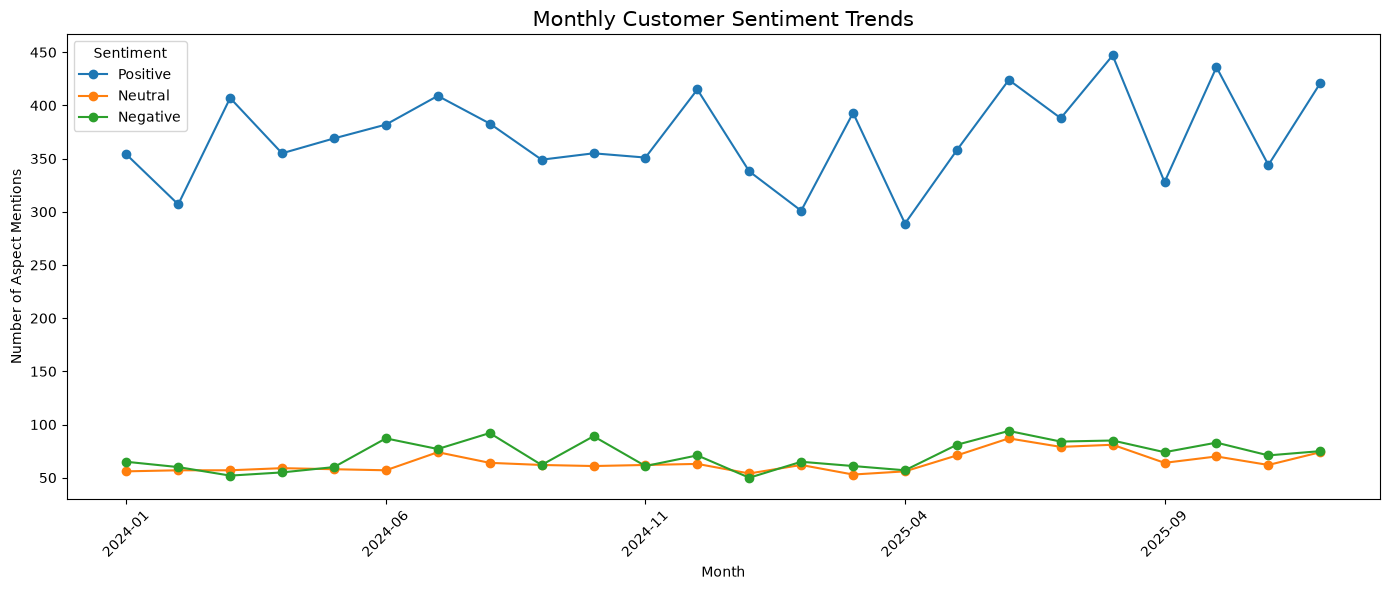

In [18]:
# ============================================================
# VISUALISE MONTHLY SENTIMENT TRENDS
# ============================================================

monthly_plot = monthly_sentiment.set_index("review_month")[
    ["Positive", "Neutral", "Negative"]
]


ax = monthly_plot.plot(
    figsize=(14, 6),
    marker="o"
)

ax.set_title(
    "Monthly Customer Sentiment Trends",
    fontsize=15
)

ax.set_xlabel("Month")
ax.set_ylabel("Number of Aspect Mentions")

plt.xticks(rotation=45)
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()

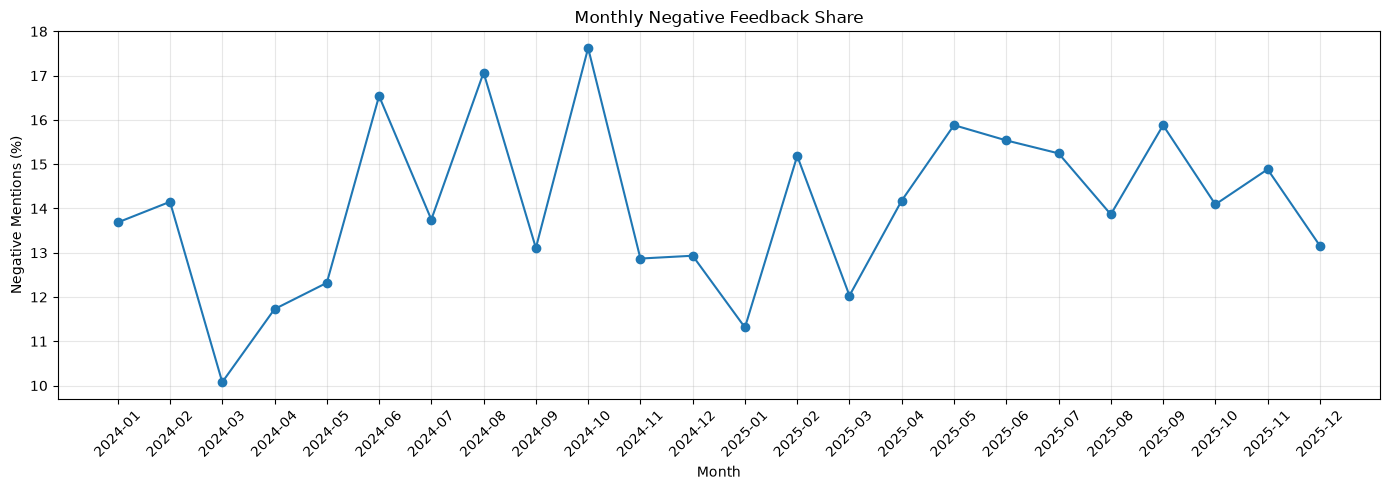

In [19]:
# ============================================================
# MONTHLY NEGATIVE SENTIMENT SHARE
# ============================================================

plt.figure(figsize=(14, 5))

plt.plot(
    monthly_sentiment["review_month"],
    monthly_sentiment["Negative (%)"],
    marker="o"
)

plt.title("Monthly Negative Feedback Share")

plt.xlabel("Month")
plt.ylabel("Negative Mentions (%)")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# 8. Customer type analysis

In [20]:
# ============================================================
# CUSTOMER TYPE SENTIMENT ANALYSIS
# ============================================================

customer_type_sentiment = pd.crosstab(
    customer_feedback["customer_type"],
    customer_feedback["sentiment"]
)


for sentiment in ["Positive", "Neutral", "Negative"]:

    if sentiment not in customer_type_sentiment.columns:
        customer_type_sentiment[sentiment] = 0


customer_type_sentiment = customer_type_sentiment[
    ["Positive", "Neutral", "Negative"]
]


customer_type_sentiment["Total Mentions"] = (
    customer_type_sentiment.sum(axis=1)
)


for sentiment in ["Positive", "Neutral", "Negative"]:

    customer_type_sentiment[f"{sentiment} (%)"] = (
        customer_type_sentiment[sentiment]
        / customer_type_sentiment["Total Mentions"]
        * 100
    )


customer_type_sentiment = (
    customer_type_sentiment.reset_index()
)


display(customer_type_sentiment)

sentiment,customer_type,Positive,Neutral,Negative,Total Mentions,Positive (%),Neutral (%),Negative (%)
0,Occasional,2113,351,425,2889,73.14,12.15,14.71
1,Rare,452,73,85,610,74.10,11.97,13.93
2,Regular,6338,1119,1201,8658,73.20,12.92,13.87


In [21]:
# ============================================================
# AVERAGE RATING BY CUSTOMER TYPE
# ============================================================

# A star rating belongs to the entire review, not to an individual aspect. 
# Therefore, calculate average ratings from the original reviews table, 
# not from the expanded aspect-level dataset.

review_customer_types = reviews[
    ["review_id", "customer_id", "rating"]
].merge(
    customers[
        ["customer_id", "customer_type"]
    ],
    on="customer_id",
    how="left"
)


customer_type_ratings = (
    review_customer_types
    .groupby("customer_type")
    .agg(
        Total_Reviews=("review_id", "nunique"),
        Average_Rating=("rating", "mean")
    )
    .reset_index()
)


customer_type_ratings["Average_Rating"] = (
    customer_type_ratings["Average_Rating"].round(2)
)


display(customer_type_ratings)

,customer_type,Total_Reviews,Average_Rating
0,Occasional,1028,4.21
1,Rare,220,4.19
2,Regular,3058,4.22


# 10. RFM customer segmentation
Identify customer groups based on their purchasing behaviour.

RFM stands for:
- Recency: How recently did the customer place an order?
- Frequency: How many orders did the customer place?
- Monetary: How much did the customer spend?

In [22]:
# ============================================================
# RFM CUSTOMER ANALYSIS
# ============================================================

# Exclude walk-in orders without a registered customer ID
registered_orders = orders.dropna(
    subset=["customer_id"]
).copy()


# Calculate a reference date one day after the last recorded order
reference_date = (
    registered_orders["order_datetime"].max()
    + pd.Timedelta(days=1)
)


# Calculate RFM metrics
rfm = (
    registered_orders
    .groupby("customer_id")
    .agg(
        Recency=(
            "order_datetime",
            lambda x: (reference_date - x.max()).days
        ),
        Frequency=("order_id", "nunique"),
        Monetary=("order_total", "sum")
    )
    .reset_index()
)


# Round monetary values
rfm["Monetary"] = rfm["Monetary"].round(2)


display(rfm.head())

print("Customers included in RFM:", len(rfm))

,customer_id,Recency,Frequency,Monetary
0,C00001,18,12,370.72
1,C00002,392,4,128.41
2,C00003,60,35,"1,325.88"
3,C00004,599,4,158.82
4,C00005,32,28,863.01


Customers included in RFM: 3841


Assign RFM scores
Each dimension receives a score from 1 to 5.
- A recent purchase receives a higher Recency score.
- More orders receive a higher Frequency score.
- Higher spending receives a higher Monetary score.
  
We use percentile ranks to avoid problems caused by tied values when using pd.qcut().

In [23]:
# ============================================================
# CALCULATE RFM SCORES
# ============================================================

# Recency: lower number of days is better
rfm["R_Score"] = np.ceil(
    rfm["Recency"].rank(
        method="average",
        ascending=False,
        pct=True
    ) * 5
).clip(1, 5).astype(int)


# Frequency: higher number of orders is better
rfm["F_Score"] = np.ceil(
    rfm["Frequency"].rank(
        method="average",
        ascending=True,
        pct=True
    ) * 5
).clip(1, 5).astype(int)


# Monetary: higher spending is better
rfm["M_Score"] = np.ceil(
    rfm["Monetary"].rank(
        method="average",
        ascending=True,
        pct=True
    ) * 5
).clip(1, 5).astype(int)


# Combined RFM score
rfm["RFM_Score"] = (
    rfm["R_Score"]
    + rfm["F_Score"]
    + rfm["M_Score"]
)


display(rfm.head())

,customer_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,C00001,18,12,370.72,5,4,4,13
1,C00002,392,4,128.41,2,3,3,8
2,C00003,60,35,"1,325.88",4,5,5,14
3,C00004,599,4,158.82,1,3,3,7
4,C00005,32,28,863.01,4,5,5,14


In [24]:
# ============================================================
# ASSIGN RFM CUSTOMER SEGMENTS
# ============================================================

def assign_rfm_segment(row):

    r = row["R_Score"]
    f = row["F_Score"]
    m = row["M_Score"]

    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"

    elif r >= 3 and f >= 4:
        return "Loyal Customers"

    elif r >= 4 and f >= 2:
        return "Potential Loyalists"

    elif r <= 2 and f >= 3:
        return "At Risk"

    elif r <= 2:
        return "Needs Attention"

    else:
        return "Regular Customers"


rfm["RFM_Segment"] = rfm.apply(
    assign_rfm_segment,
    axis=1
)


display(
    rfm.sort_values(
        "Monetary",
        ascending=False
    ).head(10)
)

,customer_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,RFM_Segment
1514,C01882,6,114,"3,991.00",5,5,5,15,Champions
2057,C02547,10,111,"3,497.40",5,5,5,15,Champions
978,C01214,19,76,"3,144.97",5,5,5,15,Champions
815,C01006,5,84,"3,066.41",5,5,5,15,Champions
826,C01017,8,84,"3,007.51",5,5,5,15,Champions
874,C01080,14,85,"2,918.44",5,5,5,15,Champions
666,C00826,19,70,"2,695.07",5,5,5,15,Champions
914,C01139,3,63,"2,436.52",5,5,5,15,Champions
1512,C01878,18,72,"2,423.92",5,5,5,15,Champions
51,C00060,11,64,"2,392.87",5,5,5,15,Champions


In [25]:
# ============================================================
# RFM SEGMENT PROFILE
# ============================================================

rfm_segment_profile = (
    rfm
    .groupby("RFM_Segment")
    .agg(
        Customer_Count=("customer_id", "nunique"),
        Average_Recency=("Recency", "mean"),
        Average_Frequency=("Frequency", "mean"),
        Average_Monetary=("Monetary", "mean"),
        Total_Revenue=("Monetary", "sum")
    )
    .reset_index()
)


rfm_segment_profile[
    [
        "Average_Recency",
        "Average_Frequency",
        "Average_Monetary",
        "Total_Revenue"
    ]
] = rfm_segment_profile[
    [
        "Average_Recency",
        "Average_Frequency",
        "Average_Monetary",
        "Total_Revenue"
    ]
].round(2)


rfm_segment_profile = rfm_segment_profile.sort_values(
    "Total_Revenue",
    ascending=False
)


display(rfm_segment_profile)

,RFM_Segment,Customer_Count,Average_Recency,Average_Frequency,Average_Monetary,Total_Revenue
1,Champions,884,25.40,21.15,738.79,"653,093.00"
0,At Risk,665,398.03,8.98,312.41,"207,752.21"
2,Loyal Customers,359,101.38,12.94,438.87,"157,554.10"
4,Potential Loyalists,464,30.86,3.78,133.17,"61,791.24"
3,Needs Attention,875,482.75,1.68,59.77,"52,294.56"
5,Regular Customers,594,106.03,2.55,87.65,"52,061.90"


# 11. Customer feedback by RFM segment

Connect purchasing behaviour with customer feedback.

For example, we can investigate whether Champions, Loyal Customers, or At Risk customers are submitting negative feedback.

In [26]:
# ============================================================
# CUSTOMER FEEDBACK BY RFM SEGMENT
# ============================================================

feedback_with_rfm = customer_feedback.merge(
    rfm[
        [
            "customer_id",
            "RFM_Segment"
        ]
    ],
    on="customer_id",
    how="left"
)

# Create a clearer summary table
feedback_by_segment = (
    feedback_with_rfm
    .groupby(["RFM_Segment", "sentiment"])
    .agg(
        Aspect_Mentions=("review_id", "size"),
        Unique_Reviews=("review_id", "nunique"),
        Unique_Customers=("customer_id", "nunique")
    )
    .reset_index()
)


display(feedback_by_segment)

,RFM_Segment,sentiment,Aspect_Mentions,Unique_Reviews,Unique_Customers
0,At Risk,Negative,301,248,193
1,At Risk,Neutral,246,215,177
2,At Risk,Positive,1662,753,412
3,Champions,Negative,934,780,469
4,Champions,Neutral,886,772,499
5,Champions,Positive,4785,2211,774
6,Loyal Customers,Negative,238,197,156
7,Loyal Customers,Neutral,191,174,134
8,Loyal Customers,Positive,1211,552,279
9,Needs Attention,Negative,71,54,53


# 12. High-value customers with negative feedback

Identify valuable customers who have submitted negative feedback, allowing to prioritise service recovery.

We define high-value customers as customers whose total recorded spending is at or above the 80th percentile of registered-customer spending.

This is a prioritisation flag, not a churn prediction.

In [27]:
# ============================================================
# HIGH-VALUE CUSTOMERS WITH NEGATIVE FEEDBACK
# ============================================================

# Calculate the high-value spending threshold
high_value_threshold = rfm["Monetary"].quantile(0.80)


# Identify high-value customers
high_value_customers = rfm.loc[
    rfm["Monetary"] >= high_value_threshold
].copy()


# Select negative feedback
negative_feedback = customer_feedback.loc[
    customer_feedback["sentiment"] == "Negative"
].copy()


# Find negative feedback from high-value customers
high_value_negative_feedback = negative_feedback.merge(
    high_value_customers[
        [
            "customer_id",
            "RFM_Segment",
            "Recency",
            "Frequency",
            "Monetary"
        ]
    ],
    on="customer_id",
    how="inner"
)


# Keep useful manager-facing columns
high_value_negative_feedback = (
    high_value_negative_feedback[
        [
            "customer_id",
            "review_id",
            "review_date",
            "aspect",
            "sentiment",
            "rating",
            "review_text",
            "RFM_Segment",
            "Recency",
            "Frequency",
            "Monetary"
        ]
    ]
    .sort_values(
        ["Monetary", "review_date"],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)


print("High-value spending threshold: €",
      round(high_value_threshold, 2))

print(
    "High-value customers with negative aspect feedback:",
    high_value_negative_feedback["customer_id"].nunique()
)

display(high_value_negative_feedback.head(20))

# A single review may appear more than once in this table if it contains multiple negative aspects. 
# That is useful for identifying exactly what the customer complained about.

High-value spending threshold: € 488.43
High-value customers with negative aspect feedback: 464


,customer_id,review_id,review_date,aspect,sentiment,rating,review_text,RFM_Segment,Recency,Frequency,Monetary
0,C01882,R003235,2025-07-15,Waiting Time,Negative,4,Service was friendly and attentive. The Marghe...,Champions,6,114,"3,991.00"
1,C01882,R002561,2025-03-21,Food,Negative,3,The atmosphere was cosy and relaxed. The team ...,Champions,6,114,"3,991.00"
2,C01882,R002410,2025-02-23,Food,Negative,2,We felt well looked after throughout the visit...,Champions,6,114,"3,991.00"
3,C01882,R001483,2024-09-13,Service,Negative,4,Our food arrived quickly. Great portions and t...,Champions,6,114,"3,991.00"
4,C02547,R003345,2025-07-31,Cleanliness,Negative,4,"Really tasty food, the Chicken Schnitzel was c...",Champions,10,111,"3,497.40"
5,C02547,R003345,2025-07-31,Waiting Time,Negative,4,"Really tasty food, the Chicken Schnitzel was c...",Champions,10,111,"3,497.40"
6,C02547,R002246,2025-01-25,Cleanliness,Negative,4,The service was quick and professional. Our wa...,Champions,10,111,"3,497.40"
7,C02547,R001722,2024-10-23,Service,Negative,4,The team was friendly and easy to talk to. Goo...,Champions,10,111,"3,497.40"
8,C02547,R001349,2024-08-18,Price,Negative,2,The Tagliatelle Bolognese was decent but a bit...,Champions,10,111,"3,497.40"
9,C02547,R000791,2024-05-22,Drinks,Negative,3,"Really tasty food, the Gnocchi Gorgonzola was ...",Champions,10,111,"3,497.40"


# 13. Export datasets for Streamlit

Save the finished analysis as reusable files. The Streamlit application will read these outputs instead of repeating the analysis every time the app starts

In [28]:
# ============================================================
#  First: PREPARE CUSTOMER FEEDBACK DETAIL
# ============================================================

customer_feedback_detail = customer_feedback[
    [
        "review_id",
        "customer_id",
        "order_id",
        "review_date",
        "review_month",
        "aspect",
        "sentiment",
        "rating",
        "review_text",
        "customer_type",
        "order_type",
        "meal_period",
        "order_total"
    ]
].copy()


display(customer_feedback_detail.head())

,review_id,customer_id,order_id,review_date,review_month,aspect,sentiment,rating,review_text,customer_type,order_type,meal_period,order_total
0,R000001,C01584,O000006,2024-01-01,2024-01,Service,Neutral,4,Our food arrived quickly. The team was friendl...,Regular,Delivery,Lunch,74.90
1,R000001,C01584,O000006,2024-01-01,2024-01,Staff,Positive,4,Our food arrived quickly. The team was friendl...,Regular,Delivery,Lunch,74.90
2,R000001,C01584,O000006,2024-01-01,2024-01,Waiting Time,Positive,4,Our food arrived quickly. The team was friendl...,Regular,Delivery,Lunch,74.90
3,R000002,C02066,O000015,2024-01-01,2024-01,Food,Positive,5,"Our food arrived quickly. Really tasty food, t...",Occasional,Delivery,Lunch,86.20
4,R000002,C02066,O000015,2024-01-01,2024-01,Waiting Time,Positive,5,"Our food arrived quickly. Really tasty food, t...",Occasional,Delivery,Lunch,86.20


Now export all the dashboard datasets:

In [29]:
# ============================================================
# EXPORT CUSTOMER INTELLIGENCE DATASETS
# ============================================================

# 1. Overall KPIs
customer_kpis.to_csv( OUTPUT_DIR / "customer_intelligence_kpis.csv", index=False )


# 2. Aspect sentiment summary
aspect_sentiment.to_csv( OUTPUT_DIR / "customer_aspect_sentiment_summary.csv", index=False )


# 3. Areas for improvement
improvement_areas.to_csv( OUTPUT_DIR / "customer_improvement_areas.csv", index=False )


# 4. Monthly sentiment trends
monthly_sentiment.to_csv( OUTPUT_DIR / "customer_monthly_sentiment.csv", index=False )


# 5. Customer type sentiment
customer_type_sentiment.to_csv( OUTPUT_DIR / "customer_feedback_by_type.csv", index=False )


# 6. Customer type ratings
customer_type_ratings.to_csv( OUTPUT_DIR / "customer_ratings_by_type.csv", index=False )


# 7. RFM customer data
rfm.to_csv( OUTPUT_DIR / "customer_rfm_segments.csv", index=False )


# 8. RFM segment profile
rfm_segment_profile.to_csv( OUTPUT_DIR / "customer_segment_profile.csv", index=False )


# 9. Feedback by RFM segment
feedback_by_segment.to_csv( OUTPUT_DIR / "customer_feedback_by_segment.csv", index=False )


# 10. High-value customers with negative feedback
high_value_negative_feedback.to_csv( OUTPUT_DIR / "high_value_negative_feedback.csv", index=False )


# 11. Detailed customer feedback
customer_feedback_detail.to_csv( OUTPUT_DIR / "customer_review_aspect_detail.csv", index=False )


print("All Customer Intelligence datasets exported successfully.")

All Customer Intelligence datasets exported successfully.


# 14. Export summary metadata

Save the main KPIs and important project information in JSON format. This is useful for the Streamlit application and project documentation

In [30]:
# ============================================================
# EXPORT CUSTOMER INTELLIGENCE SUMMARY JSON
# ============================================================

customer_summary = {
    "project": "RestroDine",
    "module": "Customer Intelligence",

    "data_type": "Synthetic demonstration data",

    "description": (
        "Customer feedback and aspect sentiment analysis "
        "using pre-generated synthetic labels."
    ),

    "reference_period": {
        "start": str(reviews["review_date"].min().date()),
        "end": str(reviews["review_date"].max().date())
    },

    "total_reviews": int(total_reviews),

    "total_customers_reviewed": int(
        total_customers_reviewed
    ),

    "average_rating": round(
        float(average_rating), 2
    ),

    "total_aspect_mentions": int(
        total_aspect_mentions
    ),

    "sentiment_distribution": {
        "positive_percentage": round(
            float(positive_share), 2
        ),
        "neutral_percentage": round(
            float(neutral_share), 2
        ),
        "negative_percentage": round(
            float(negative_share), 2
        )
    },

    "rfm": {
        "customers_analysed": int(len(rfm)),
        "high_value_spending_threshold": round(
            float(high_value_threshold), 2
        ),
        "high_value_customers_with_negative_feedback": int(
            high_value_negative_feedback["customer_id"].nunique()
        )
    },

    "methodology_note": (
        "Aspect sentiment values are supplied synthetic annotations. "
        "They are descriptive inputs to this dashboard, not predictions "
        "from a trained NLP model."
    )
}


with open(
    METADATA_DIR / "customer_intelligence_summary.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        customer_summary,
        file,
        indent=4,
        ensure_ascii=False
    )


print("Summary JSON exported successfully.")

display(customer_summary)

Summary JSON exported successfully.


{'project': 'RestroDine',
 'module': 'Customer Intelligence',
 'data_type': 'Synthetic demonstration data',
 'description': 'Customer feedback and aspect sentiment analysis using pre-generated synthetic labels.',
 'reference_period': {'start': '2024-01-01', 'end': '2025-12-31'},
 'total_reviews': 4306,
 'total_customers_reviewed': 2030,
 'average_rating': 4.21,
 'total_aspect_mentions': 12157,
 'sentiment_distribution': {'positive_percentage': 73.23,
  'neutral_percentage': 12.69,
  'negative_percentage': 14.07},
 'rfm': {'customers_analysed': 3841,
  'high_value_spending_threshold': 488.43,
  'high_value_customers_with_negative_feedback': 464},
 'methodology_note': 'Aspect sentiment values are supplied synthetic annotations. They are descriptive inputs to this dashboard, not predictions from a trained NLP model.'}

# 14. Final export verification

In [31]:
# ============================================================
# VERIFY EXPORTED FILES
# ============================================================

exported_files = sorted(
    OUTPUT_DIR.glob("customer_*")
)

exported_files += sorted(
    OUTPUT_DIR.glob("high_value_negative_feedback.csv")
)

for file_path in exported_files:

    if file_path.exists():

        print(
            f"{file_path.name:<45} "
            f"{file_path.stat().st_size:>10,} bytes"
        )


print("\nCustomer Intelligence notebook completed.")

customer_aspect_sentiment_summary.csv                727 bytes
customer_feedback_by_segment.csv                     692 bytes
customer_feedback_by_type.csv                        336 bytes
customer_improvement_areas.csv                       531 bytes
customer_intelligence_kpis.csv                       194 bytes
customer_monthly_sentiment.csv                     1,046 bytes
customer_ratings_by_type.csv                          96 bytes
customer_review_aspect_detail.csv              2,652,868 bytes
customer_rfm_segments.csv                        159,736 bytes
customer_segment_profile.csv                         369 bytes
high_value_negative_feedback.csv                 199,726 bytes

Customer Intelligence notebook completed.
